# 9층 · 생성형 AI 실습

프롬프트를 AI에게 보내 받은 파이썬 코드입니다. 위에서부터 셀을 차례로 실행해 보세요.
데이터는 GitHub 저장소에서 바로 불러옵니다.

저장된 결과는 Python 3.13.18 · pandas 3.0.5 · scikit-learn 1.9.1 · NumPy 2.5.3 · matplotlib 3.11.2 로 실행한 것입니다. Colab에서는 라이브러리 버전에 따라 소수점이 조금 다를 수 있습니다.

## 실습 1 · 배터리 5개로 MSE·RMSE·MAE·R² 직접 확인

**프롬프트**

> 배터리 5개의 실제 수명은 1334, 704, 1101, 568, 1371이고
> 예측은 1200, 850, 1010, 640, 1330이에요.
> 잔차와 MSE, RMSE, MAE, R²를 계산해 주세요. 공식도 주석으로 달아 주세요.

In [ ]:
import numpy as np
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

actual = np.array([1334, 704, 1101, 568, 1371])
pred   = np.array([1200, 850, 1010, 640, 1330])

resid = actual - pred                      # 잔차 = 실제 − 예측
print("잔차:", resid)
mse = mean_squared_error(actual, pred)     # 잔차² 의 평균
print("MSE :", round(mse, 1))
print("RMSE:", round(np.sqrt(mse), 1))      # √MSE → 원래 단위(사이클)
print("MAE :", mean_absolute_error(actual, pred))   # |잔차| 의 평균
print("R²  :", round(r2_score(actual, pred), 3))     # 1 − SSE ÷ SST

잔차: [ 134 -146   91  -72   41]
MSE : 10883.6
RMSE: 104.3
MAE : 96.8
R²  : 0.898


**박사의 한 줄 판단** — MSE 10,883.6, RMSE 104.3, MAE 96.8 — 본문 손계산과 같습니다. R² 0.898은 배터리 5개만으로 낸 값이라 참고로만 봅니다.

## 실습 2 · 어떤 특성이 수명을 가장 많이 설명하나 — 순열 중요도

**프롬프트**

> battery_sim.csv로 랜덤포레스트 회귀를 만든 뒤
> 특성마다 값을 섞어 보면 시험 점수가 얼마나 떨어지는지(순열 중요도) 계산해 주세요.
> 막대그래프로 보여 주세요(그래프 글자는 영어).

daily_use             0.024
depth_of_discharge    0.212
fast_charge           0.325
avg_temp              1.240


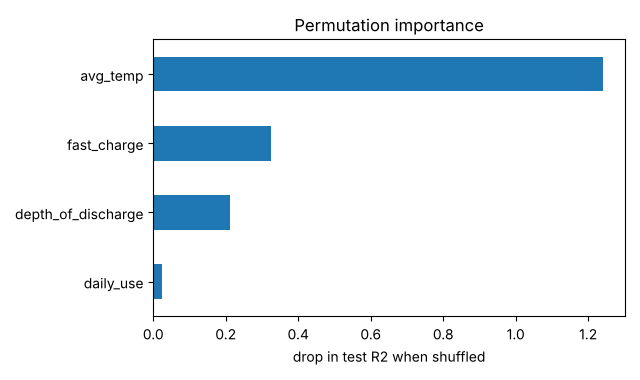

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance

df = pd.read_csv("https://raw.githubusercontent.com/adminmrobo/python_machine_learning_lab/main/data/battery_sim.csv")
X = df[["avg_temp", "fast_charge", "depth_of_discharge", "daily_use"]]
y = df["cycles"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

rf = RandomForestRegressor(n_estimators=300, random_state=0).fit(X_train, y_train)
imp = permutation_importance(rf, X_test, y_test, n_repeats=10, random_state=0)
s = pd.Series(imp.importances_mean, index=X.columns).sort_values()
print((s.round(3)).to_string())

s.plot.barh()
plt.xlabel("drop in test R2 when shuffled"); plt.title("Permutation importance")
plt.show()

**박사의 한 줄 판단** — 평균 온도를 섞으면 시험 R²가 1.24만큼 떨어져 가장 중요한 특성입니다. 중요도는 “모델이 많이 기대는 정도”이지 “원인”이 아니라는 점은 계수 읽기와 같습니다.